# 🤘 Cache Me If You Can — Act II: the stash

In Act I, decode produced one token every few milliseconds, and the speed hardly changed as the prompt grew. That only works because of the **KV cache**. In this act you build one into a real model and find out:

1. What problem the KV cache solves.
2. What goes into it: the **K** (key) and **V** (value) vectors.
3. Why the **Q** (query) vectors are not cached.
4. What it costs: memory.

For this act and Act IV you work with **GPT-2 small** (124 million parameters, 12 layers, 12 attention heads), with its real weights, already on this machine. The model of Act I is thousands of lines of code; GPT-2 is simple enough to read in full, which is what you need to understand the KV cache by building it. The rest of the model (embeddings, layer norms, projections, feed-forward layers) is already written in TT-NN in `common/gpt2.py`. What is left for you: the attention and the cache, in this notebook.

In [ ]:
import sys
from pathlib import Path
REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / "2026" / "common").is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "2026"))
from common import config, wait_for_warmup
wait_for_warmup()
import math, time
import torch, ttnn
import matplotlib.pyplot as plt
from common.gpt2 import GPT2, causal_mask

device = ttnn.open_device(device_id=0)
model = GPT2(device, config.local_weights(config.GPT2_MODEL_ID))
tok = model.tokenizer
print(f"GPT-2: {model.n_layers} layers, {model.n_heads} heads of size {model.d_head}, at most {model.max_positions} positions")

## 1. Attention, from the formula

A model generates text one token at a time. To choose token $t+1$, the newest token $t$ has to "look at" all the tokens before it. That is what attention does.

Every token $i$ is turned into three vectors by multiplying its hidden state $x_i$ with three learned matrices:

$$q_i = x_i W_Q, \qquad k_i = x_i W_K, \qquad v_i = x_i W_V$$

- the **query** $q_i$: what token $i$ is looking for,
- the **key** $k_i$: what token $i$ offers to be found by,
- the **value** $v_i$: what token $i$ passes on when it is found.

The output of attention for token $t$ is a weighted average of the values of tokens $1$ to $t$. The weights come from how well $q_t$ matches each key:

$$o_t = \sum_{i \le t} \operatorname{softmax}_i\!\left(\frac{q_t \cdot k_i}{\sqrt{d}}\right) v_i$$

where $d$ is the size of each vector (64 per head in GPT-2). For all $T$ tokens at once, with the vectors stacked into matrices $Q, K, V$:

$$O = \operatorname{softmax}\!\left(\frac{Q K^\top}{\sqrt{d}} + M\right) V$$

$M$ is the **causal mask**: $-\infty$ wherever a token would look at a later token, so that after the softmax those weights become $0$. A token never sees the future.

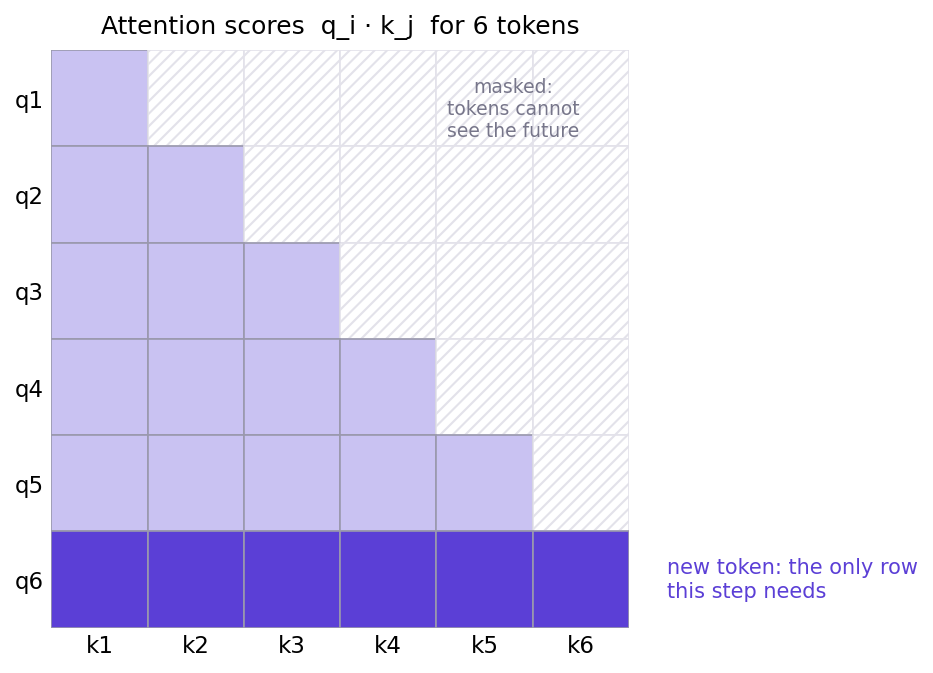

**Fill in `attention`**: three TT-NN calls (`ttnn.matmul`, `ttnn.softmax`, `ttnn.matmul`), a transpose of $K$ (`ttnn.permute`), the $1/\sqrt{d}$ scale, and the mask, which is added when it is not `None`. The shapes are `[1, heads, tokens, 64]`.

The cell then compares your result with PyTorch using the **relative error**: the size of the difference divided by the size of the expected result. It cannot be zero: the card computes in bfloat16, which keeps about 3 significant digits, so 2-3% is normal, while a mistake gives tens of percent.

To see how any of these functions is called, run `help(ttnn.permute)` (or the function you need) in a cell; Act 0 lists more ways to look things up.

In [ ]:
def attention(q, k, v, mask):
    """q: [1, H, Tq, d]; k, v: [1, H, Tk, d]; mask: [1, 1, Tq, Tk] or None.  Returns [1, H, Tq, d]."""
    # >>> YOUR CODE HERE: follow the formula above step by step; you need ttnn.matmul, ttnn.permute (to transpose k), ttnn.add and ttnn.softmax
    raise NotImplementedError("follow the formula above step by step; you need ttnn.matmul, ttnn.permute (to transpose k), ttnn.add and ttnn.softmax")
    # <<<

# check against PyTorch on random data
torch.manual_seed(0)
q, k, v = (torch.randn(1, 12, 37, 64) for _ in range(3))
m = torch.triu(torch.full((37, 37), float("-inf")), diagonal=1).view(1, 1, 37, 37)
expected = torch.softmax(q @ k.transpose(-1, -2) / 8 + m, dim=-1) @ v
to_dev = lambda t: ttnn.from_torch(t.to(torch.bfloat16), layout=ttnn.TILE_LAYOUT, device=device)
got = ttnn.to_torch(attention(to_dev(q), to_dev(k), to_dev(v), to_dev(m))).float()
error = ((got - expected).norm() / expected.norm()).item()     # relative error
print(f"differs from PyTorch by {100 * error:.1f}%  (bfloat16 rounding; a mistake gives tens of percent)")
assert error < 0.10, "attention() disagrees with the formula - check the transpose, the scale and the mask"

## 2. Generating without a cache

Now the whole model. One **forward pass** runs every token through the 12 layers. In each layer: compute $Q, K, V$, run your attention, then the rest of the layer.

To generate, call it in a loop: run the whole text so far, take the most likely next token, append it, repeat. Read `forward_full` and `generate_without_cache` below; there is nothing to fill in.

One thing to expect: the **first** run compiles kernels for every new length the model sees (the warm-up from Act 0 did this for the exact prompt below, so it should be quick). Later runs reuse them.

Expect plausible but slightly odd text: GPT-2 small is a small model from 2019, and the loop always takes the single most likely next token, which makes it repeat itself. It is the same text the original GPT-2 writes in PyTorch at the same precision.

In [ ]:
def forward_full(token_ids):
    """Runs ALL tokens through the model. Returns the logits for the next token."""
    T = len(token_ids)
    x = model.embed(token_ids, start_pos=0)
    mask = causal_mask(device, n_new=T, n_total=T)
    for layer in range(model.n_layers):
        q, k, v = model.qkv(x, layer)
        x = model.finish_block(x, attention(q, k, v, mask), layer)
    return model.next_token_logits(x)

def generate_without_cache(prompt, n_new):
    ids = tok.encode(prompt)
    n_prompt, step_ms = len(ids), []
    logits = forward_full(ids)
    for _ in range(n_new):
        ids.append(int(logits.argmax()))
        t0 = time.perf_counter()
        logits = forward_full(ids)            # the whole text again, every step
        step_ms.append((time.perf_counter() - t0) * 1e3)
    return tok.decode(ids[n_prompt:]), step_ms

text_plain, ms_plain = generate_without_cache(config.ACT2_PROMPT, config.ACT2_NEW_TOKENS)
print(config.ACT2_PROMPT + text_plain)

## 3. What the cache stores, and why not Q

Look at what each step of that loop recomputed. To choose the next token, the model needs only the **last row** of the attention matrix: the query of the newest token against the keys of all tokens, and then their values. But `forward_full` recomputed **everything**: the $Q$, $K$ and $V$ of every earlier token, in every layer, and every row of the matrix. All of that was already computed in earlier steps.

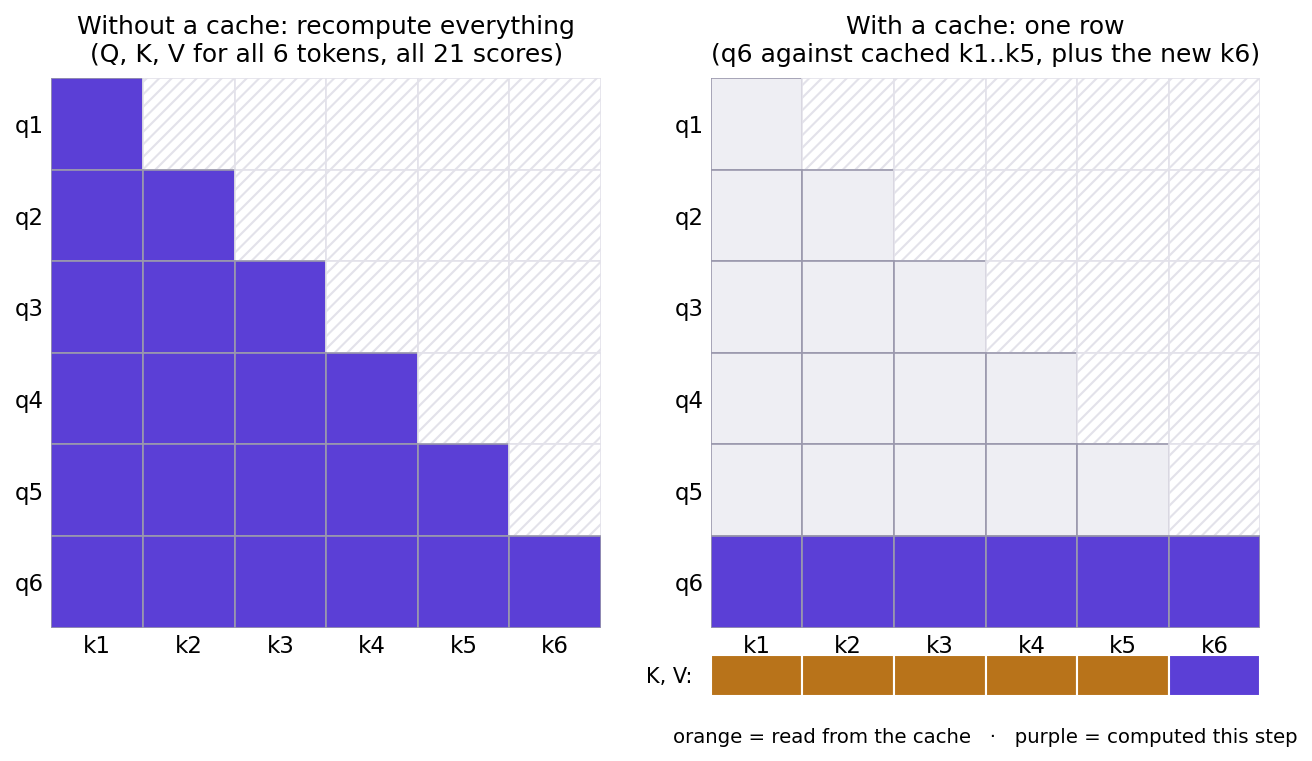

**What is in the cache:** the keys $k_i$ and values $v_i$ of every earlier token, in every layer and every head. Every future token will need them again, because each new row of the attention matrix reads all the columns.

**Why not the queries:** the query $q_i$ is used in one row only, row $i$, and that row was used when token $i$ was processed. No later step reads it. A query cache would store numbers nobody ever reads.

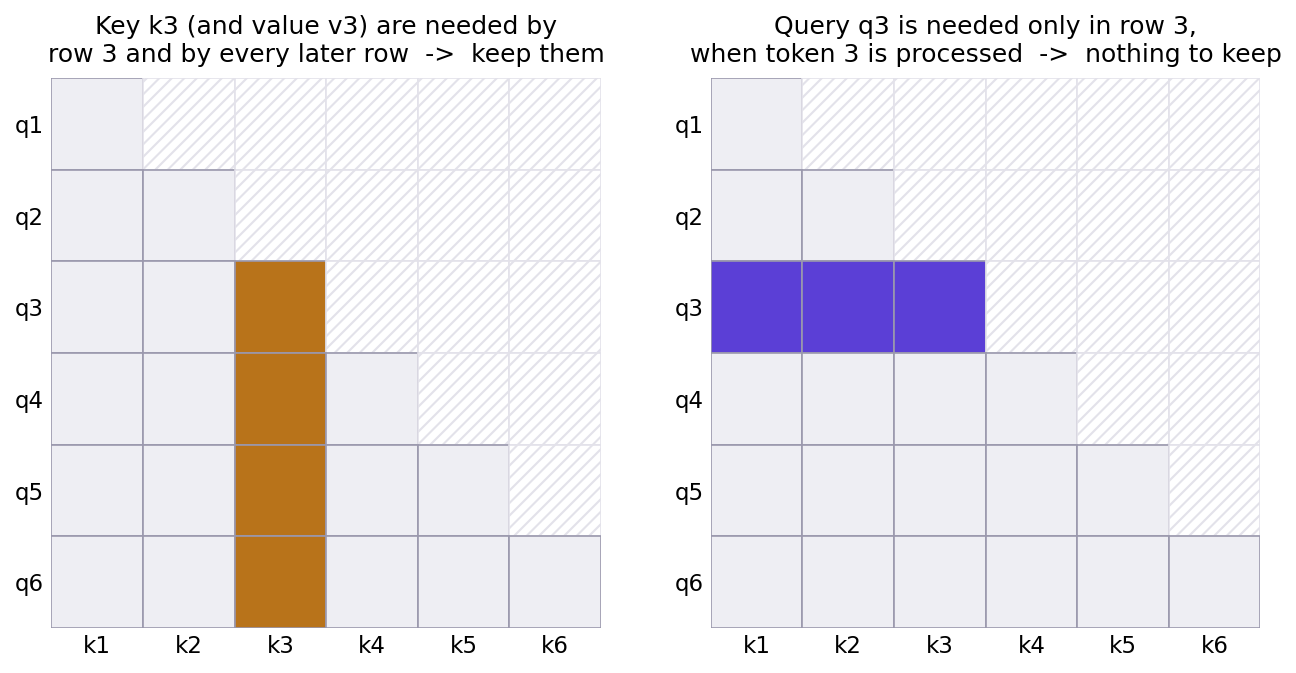

You can check this with one cell: run attention for a whole sequence, then run it again with only the **last** query against all keys and values. The last row comes out the same:

In [ ]:
ids = tok.encode(config.ACT2_PROMPT)
x = model.embed(ids, start_pos=0)
q, k, v = model.qkv(x, layer=0)
T = len(ids)
all_rows = ttnn.to_torch(attention(q, k, v, causal_mask(device, T, T))).float()   # every token's output
q_last = q[:, :, T - 1:T, :]                                                          # only the newest query
last_row = ttnn.to_torch(attention(q_last, k, v, None)).float()                      # one row, no mask needed
error = ((all_rows[:, :, -1] - last_row[:, :, 0]).norm() / all_rows[:, :, -1].norm()).item()
print(f"newest token's output, full computation vs only its own query: {100 * error:.2f}% apart")

## 4. Generating with a cache

The cache below keeps, for every layer, the keys and values of all tokens seen so far. Each step now sends **only the new token** through the model. In every layer that token gets its own $q, k, v$. Its $k$ and $v$ are added to the cache, and its $q$ attends to everything in the cache.

**Fill in `KVCache.append`.** Add the new keys and values to the stored ones along the token axis (`dim=2` of `[1, heads, tokens, 64]`) with `ttnn.concat`, store the result, and return the full keys and values. The first call for a layer has nothing stored yet.

In [ ]:
class KVCache:
    def __init__(self, n_layers):
        self.k = [None] * n_layers      # per layer: [1, heads, tokens so far, 64]
        self.v = [None] * n_layers
        self.length = 0                 # number of tokens stored

    def append(self, layer, k_new, v_new):
        """Store the keys/values of the new token(s); return ALL keys and values for this layer."""
        # >>> YOUR CODE HERE: ttnn.concat joins a list of tensors along one dimension; which dimension counts tokens, and what is stored before the first call?
        raise NotImplementedError("ttnn.concat joins a list of tensors along one dimension; which dimension counts tokens, and what is stored before the first call?")
        # <<<

def forward_with_cache(cache, new_ids):
    """Runs only the NEW tokens through the model, attending to everything stored in the cache."""
    x = model.embed(new_ids, start_pos=cache.length)
    for layer in range(model.n_layers):
        q, k, v = model.qkv(x, layer)
        k_all, v_all = cache.append(layer, k, v)
        mask = causal_mask(device, n_new=len(new_ids), n_total=k_all.shape[2])
        x = model.finish_block(x, attention(q, k_all, v_all, mask), layer)
    cache.length += len(new_ids)
    return model.next_token_logits(x)

def generate_with_cache(prompt, n_new):
    ids = tok.encode(prompt)
    n_prompt, step_ms = len(ids), []
    cache = KVCache(model.n_layers)
    logits = forward_with_cache(cache, ids)          # the prompt once: this is prefill
    for _ in range(n_new):
        ids.append(int(logits.argmax()))
        t0 = time.perf_counter()
        logits = forward_with_cache(cache, ids[-1:])  # only the newest token: this is decode
        step_ms.append((time.perf_counter() - t0) * 1e3)
    return tok.decode(ids[n_prompt:]), step_ms

text_cached, ms_cached = generate_with_cache(config.ACT2_PROMPT, config.ACT2_NEW_TOKENS)
print(config.ACT2_PROMPT + text_cached)
print(f"\nidentical text with and without the cache: {text_cached == text_plain}")

The text is the same. The cache is not an approximation: it gives exactly the same result, without recomputing anything.

## 5. What it saves

The difference grows with the length of the text. For each context length below, the cell builds a cache of that many tokens and times **one** generation step both ways. Each length is run once before timing, because a new length compiles new kernels.

In [ ]:
def time_ms(fn, repeats=5):
    fn()                                     # compiles kernels for this length, not timed
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append((time.perf_counter() - t0) * 1e3)
    return sorted(times)[len(times) // 2]   # the median ignores the odd slow run

filler = tok.encode(" The chip reads the weights again for every token it writes.") * 200

def one_cached_step(cache):
    """One generation step on a copy of the cache, so the stored cache keeps its length."""
    trial = KVCache(model.n_layers)
    trial.k, trial.v, trial.length = list(cache.k), list(cache.v), cache.length
    return forward_with_cache(trial, [262])

plain_ms, cached_ms = [], []
for n in config.ACT2_CONTEXT_LENGTHS:
    context = filler[:n]
    cache = KVCache(model.n_layers)
    forward_with_cache(cache, context)                       # a cache holding n tokens
    plain_ms.append(time_ms(lambda: forward_full(context + [262])))
    cached_ms.append(time_ms(lambda: one_cached_step(cache)))
    print(f"{n:>4} tokens of context:  without cache {plain_ms[-1]:6.1f} ms   with cache {cached_ms[-1]:6.1f} ms")

plt.figure(figsize=(6, 3.6))
plt.plot(config.ACT2_CONTEXT_LENGTHS, plain_ms, "o-", label="without cache: recompute everything")
plt.plot(config.ACT2_CONTEXT_LENGTHS, cached_ms, "s-", label="with cache: only the new token")
plt.xlabel("tokens of context"); plt.ylabel("ms per generated token"); plt.ylim(bottom=0)
plt.legend(); plt.grid(alpha=0.3); plt.title("GPT-2 on this card, one generation step"); plt.show()

for n, p, c in zip(config.ACT2_CONTEXT_LENGTHS, plain_ms, cached_ms):
    speed = f"{p / c:.1f}x faster" if p / c >= 1.05 else (f"{c / p:.1f}x slower" if p / c <= 0.95 else "about as fast")
    print(f"{n:>4} tokens of context: the cache processes {n + 1}x fewer tokens per step, and the step is {speed}")

With the cache, the cost of a step grows much more slowly with the length of the text than without it. (It still grows a little: the newest token's attention reads every stored key and value.)

The last lines show something else: the cache cuts the work per step by hundreds of times, yet the time drops much less, and with a short text the cached step can even be a little slower. Two reasons. Every step has to update the cache, here by concatenating the new key and value, which adds two operations per layer. And the rest of the model has costs the cache does not touch: for a model as small as GPT-2, most of each step is the fixed cost of sending about 300 commands to the card, one per operation. The model in Act I removes that cost with trace.

The lesson holds well beyond this notebook: a large saving in work only shows up in time when the work is what takes the time. Measure before you believe a speed-up.

## 6. What it costs: memory

The cache trades computation for memory. For each token, in each layer, it stores one key and one value vector for each **KV head**, every number in 2 bytes (`bfloat16`).

**Fill in `kv_cache_bytes`**, then look at the numbers for GPT-2 and for the model of Act I.

In [ ]:
def kv_cache_bytes(n_layers, n_kv_heads, d_head, n_tokens, n_users=1, bytes_per_number=2):
    """Total size of the KV cache in bytes."""
    # >>> YOUR CODE HERE: first count the bytes stored for one token in one layer (the text above says what is stored), then scale up
    raise NotImplementedError("first count the bytes stored for one token in one layer (the text above says what is stored), then scale up")
    # <<<

MB, GB = 1e6, 1e9
print(f"GPT-2, 1024 tokens, one user: {kv_cache_bytes(12, 12, 64, 1024) / MB:6.1f} MB")
# The Act I model: 28 layers, 2 key/value heads of size 128
for n_tokens in (1_000, 4_000, 32_000):
    print(f"Act I model, {n_tokens:>6} tokens, one user: {kv_cache_bytes(28, 2, 128, n_tokens) / MB:7.1f} MB")
per_user_4k = kv_cache_bytes(28, 2, 128, 4_000)
free = 12 * GB - 1.8 * GB          # the n150's 12 GB minus about 1.8 GB of weights
print(f"\nusers that fit on a 12 GB n150 at 4,000 tokens each: about {int(free // per_user_4k)}")

Two things to notice.

**The cache grows with every token and every user.** On a 12 GB card the weights take under 2 GB; the rest goes to caches. How many users a card can serve, and with how much context, comes down to this formula. You will see it again in Act III.

**It gets large.** As a conversation grows, so does its cache: at long context it reaches gigabytes. In practice it is worse, because a server keeps a cache for every conversation it handles at the same time (two people chatting, or an agent with several sub-agents). That is why the architectures of today's frontier models all reduce the size of the KV cache in one way or another.

### Optional: how long can the context get?

Estimate from the formula how many tokens of context one user could have on this card before the cache no longer fits. When the cache runs out of memory, production servers store it in fixed-size **pages** (like virtual memory), so users can come and go without fragmenting the memory. More in Talk 3.

**Free the card for the next act.** A program that has used the card keeps it until it stops, so the last cell stops this notebook's kernel. Your outputs stay on the page; VS Code will show the kernel as stopped, which is expected.

In [ ]:
ttnn.close_device(device)
print("Act II done.")
from common import release_card
release_card()